# Figure 3: syllable transition structure

Reads `transition_structure_data.pkl`, made by Cell T1 of `data_figs`.

* **A**: transition diagram of one zebra finch, regular air and heliox. Arrow darkness is the probability of moving from one syllable to the next.
* **B**: share of each condition's transitions that fall on transition types also seen in the other condition (mean ± SEM across birds).
* **C**: transition diagrams of one starling: all transitions, transitions seen in both conditions (shared), and transitions seen in only one (specific). Nodes sit at the centre of each syllable type in the UMAP embedding.
* **D**: ISI on condition-specific vs shared transitions in starlings, `isi ~ transition class + (1 | bird)`, one model per condition, with 95% CI.


In [1]:
# Setup: paths, figure style, data
import os
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx
import statsmodels.formula.api as smf
from scipy.stats import mannwhitneyu
from matplotlib.ticker import FuncFormatter

# Paths relative to the repository, so a fresh clone runs without edits (from the repo folder or
# from notebooks/). To use other copies, e.g. on the cluster: export HELIOX_DATA_DIR=/path/to/data/derived
REPO = os.path.dirname(os.getcwd()) if os.path.basename(os.getcwd()) == 'notebooks' else os.getcwd()
DATA_DIR = os.environ.get('HELIOX_DATA_DIR', os.path.join(REPO, 'data'))
FIG_DIR = os.environ.get('HELIOX_FIG_DIR', os.path.join(REPO, 'figures'))
DATA_PATH = os.path.join(DATA_DIR, 'transition_structure_data.pkl')
os.makedirs(FIG_DIR, exist_ok=True)

plt.rcParams.update({'font.size': 15, 'axes.titlesize': 19, 'axes.labelsize': 16,
                     'xtick.labelsize': 15, 'ytick.labelsize': 14, 'savefig.dpi': 300,
                     'axes.spines.top': False, 'axes.spines.right': False})

tr = pd.read_pickle(DATA_PATH)
zf_t, st_t = tr['zf_transitions'], tr['starling_transitions']
print(f"{len(zf_t)} zebra finch and {len(st_t)} starling transitions")

58661 zebra finch and 60038 starling transitions


In [2]:
# Shared and condition-specific transitions, and the ISI models
# The original analysis counted a transition type as present in a condition once it occurred there
# MIN_COUNT times: 1 for both species everywhere, except the starling bars of B, which used 5.
MIN_COUNT = {'zebra_finch': 1, 'starling': 1}
MIN_COUNT_STARLING_B = 5


def classify(t, min_count):
    """Each transition with how often its type (from -> to) occurs in its own and in the other condition
    of that bird. own_ok: the type counts as present in this condition; shared: present in both."""
    n = t.groupby(['bird', 'condition', 'from_label', 'to_label']).size().unstack('condition', fill_value=0)
    n = n.reindex(columns=['heliox', 'regair'], fill_value=0).reset_index()
    out = t.merge(n, on=['bird', 'from_label', 'to_label'], how='left')
    own = np.where(out['condition'] == 'heliox', out['heliox'], out['regair'])
    other = np.where(out['condition'] == 'heliox', out['regair'], out['heliox'])
    return out.assign(own_ok=own >= min_count, shared=(own >= min_count) & (other >= min_count))


def per_bird_shares(t, min_count):
    """Per bird and condition: transitions on types present in that condition, and the share on shared types."""
    c = classify(t, min_count)
    c = c[c['own_ok']]
    g = c.groupby(['bird', 'condition'])['shared'].agg(n='size', n_shared='sum').reset_index()
    return g.assign(pct_shared=100 * g['n_shared'] / g['n'])


shares = {'zebra_finch': per_bird_shares(zf_t, MIN_COUNT['zebra_finch']),
          'starling': per_bird_shares(st_t, MIN_COUNT_STARLING_B)}
bars = pd.concat([s.groupby('condition')['pct_shared'].agg(['mean', 'sem']).assign(species=sp)
                  for sp, s in shares.items()]).reset_index()

# Species comparison: share of a bird's transitions (both conditions together) on condition-specific types
totals = {sp: s.groupby('bird')[['n', 'n_shared']].sum() for sp, s in shares.items()}
specific_pct = {sp: 100 * (t['n'] - t['n_shared']) / t['n'] for sp, t in totals.items()}
mwu = mannwhitneyu(specific_pct['zebra_finch'], specific_pct['starling'], alternative='less')

# D: starlings, ISI on condition-specific vs shared transitions, one model per condition
st_c = classify(st_t, MIN_COUNT['starling'])
st_c = st_c.assign(specific=(~st_c['shared']).astype(int))
st_c = st_c[np.isfinite(st_c['isi_s'])]      # a transition counts as a type above even without a usable ISI
print(f"{int((~np.isfinite(st_t['isi_s'])).sum())} starling transitions without a usable ISI left out of the models")
models = {}
for cond in ('heliox', 'regair'):
    d = st_c[st_c['condition'] == cond]
    if cond == 'regair':
        # as in the original analysis: only birds with at least 10 ISIs of each class enter this model
        n = d.groupby(['bird', 'specific']).size().unstack(fill_value=0)
        d = d[d['bird'].isin(n.index[(n >= 10).all(axis=1)])]
    # default fit (REML), as in the original analysis
    models[cond] = smf.mixedlm('isi_s ~ specific', d, groups=d['bird']).fit()

effects = pd.DataFrame([dict(condition=c, beta=m.params['specific'], se=m.bse['specific'], z=m.tvalues['specific'],
                             p=m.pvalues['specific'], ci_lo=m.conf_int().loc['specific', 0],
                             ci_hi=m.conf_int().loc['specific', 1], birds=m.model.n_groups)
                        for c, m in models.items()])
print(bars.round(2).to_string(index=False))
print(f"\ncondition-specific share, mean ± SEM: zebra finch {specific_pct['zebra_finch'].mean():.2f} ± "
      f"{specific_pct['zebra_finch'].sem():.2f}%, starling {specific_pct['starling'].mean():.2f} ± "
      f"{specific_pct['starling'].sem():.2f}%; Mann-Whitney U = {mwu.statistic:.0f}, P = {mwu.pvalue:.4f} (one-tailed)")
print('\nISI, specific - shared (s):')
print(effects.to_string(index=False, float_format=lambda v: f'{v:.4g}'))

0 starling transitions without a usable ISI left out of the models


/home/AD/lstanwic/anaconda3/lib/python3.8/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/home/AD/lstanwic/anaconda3/lib/python3.8/site-packages/statsmodels/regression/mixed_linear_model.py:2201: ConvergenceWarning: Retrying MixedLM optimization with lbfgs
  warnings.warn(


condition  mean   sem     species
   heliox 99.94  0.04 zebra_finch
   regair 99.77  0.13 zebra_finch
   heliox 84.08  4.83    starling
   regair 64.34 10.07    starling

condition-specific share, mean ± SEM: zebra finch 0.19 ± 0.09%, starling 33.33 ± 7.66%; Mann-Whitney U = 0, P = 0.0011 (one-tailed)

ISI, specific - shared (s):
condition    beta       se      z         p   ci_lo    ci_hi  birds
   heliox 0.07838  0.01459   5.37 7.858e-08 0.04977    0.107      6
   regair -0.1038 0.005622 -18.46 4.038e-76 -0.1148 -0.09279      6


/home/AD/lstanwic/anaconda3/lib/python3.8/site-packages/statsmodels/regression/mixed_linear_model.py:2238: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


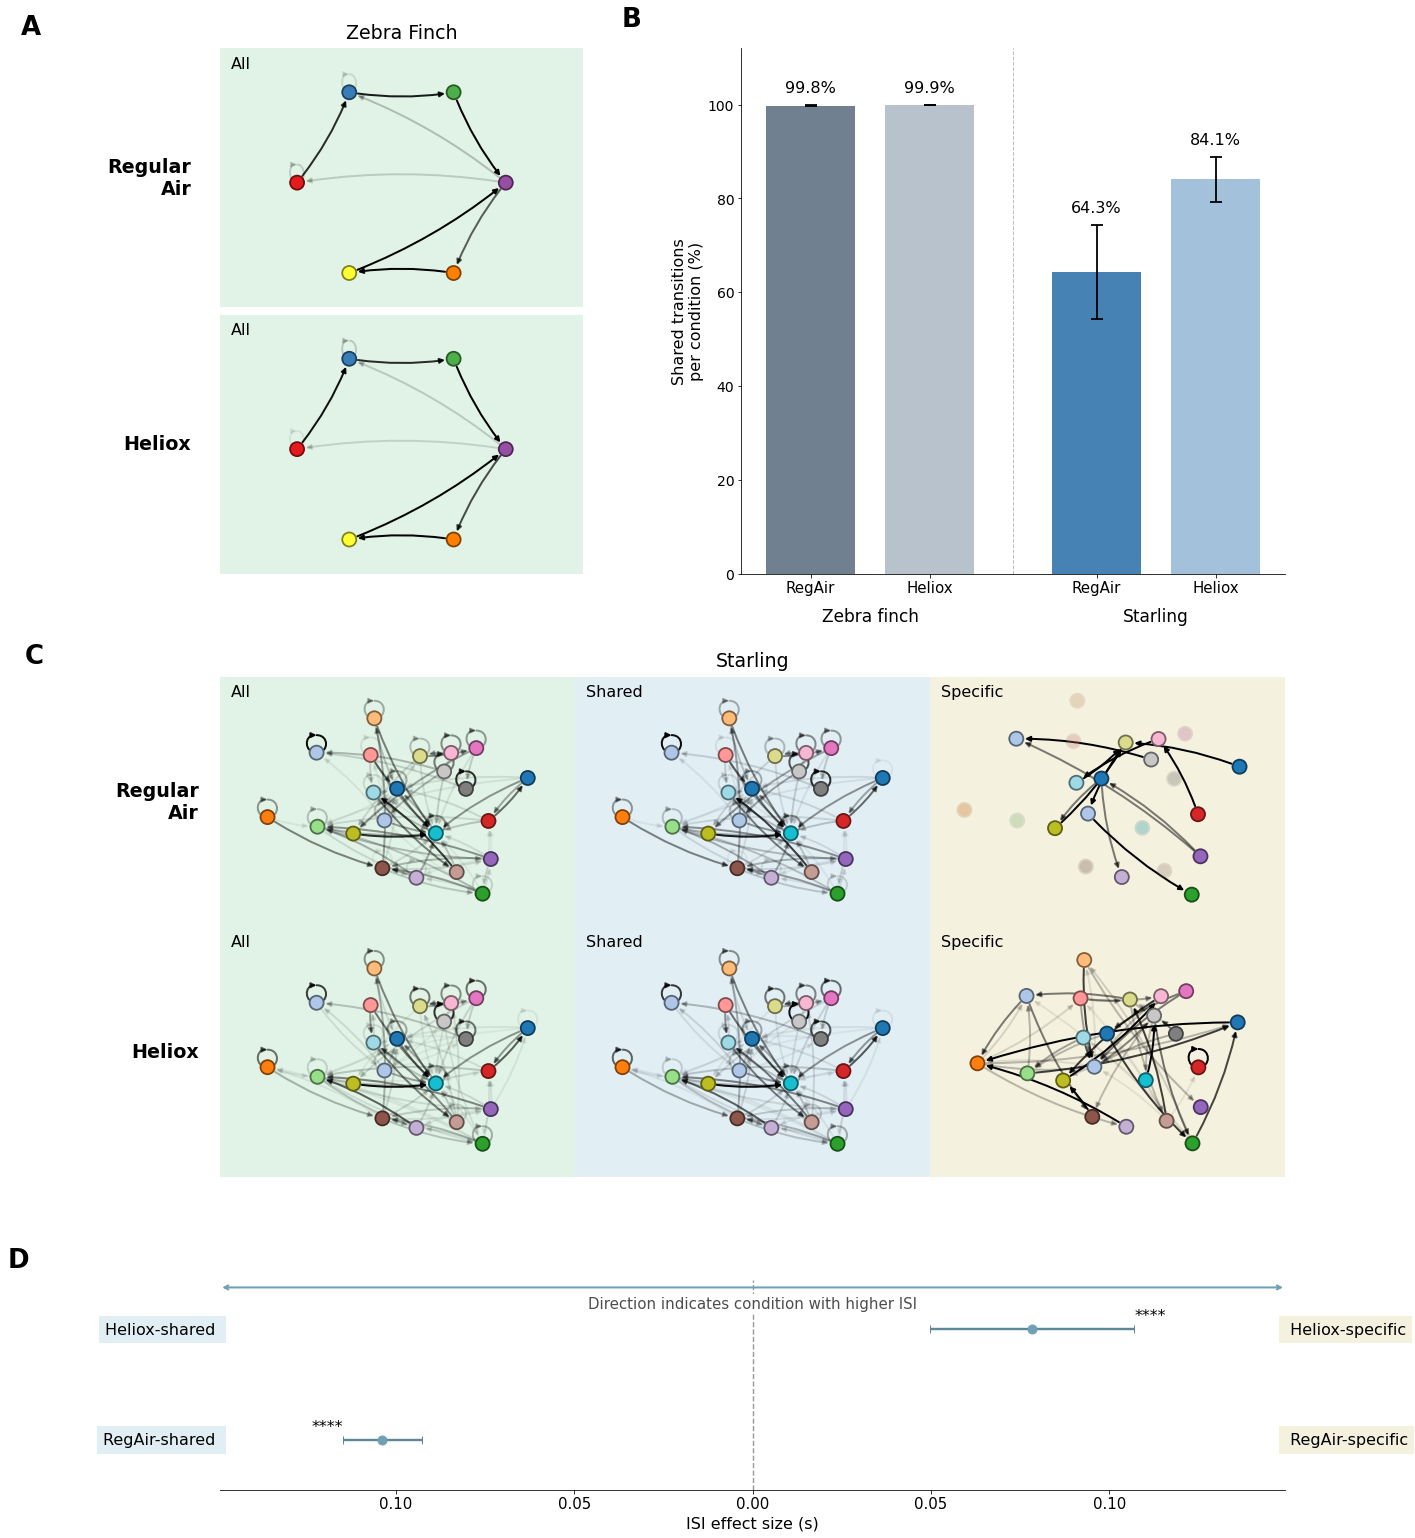

In [3]:
# Figure 3
BACKGROUND = {'All': '#e1f3e6', 'Shared': '#e1eff5', 'Specific': '#f4f1df'}
ROWS = [('regair', 'Regular\nAir'), ('heliox', 'Heliox')]
MIN_EDGE = 0.05      # transitions rarer than this (probability from the first syllable) are not drawn


def song_sequences(d):
    """Each song's labels in order."""
    order = ['song', 'position'] if 'position' in d.columns else ['song']
    return [g['label'].to_numpy() for _, g in d.sort_values(order, kind='mergesort').groupby('song', sort=False)]


def transition_probabilities(sequences, allowed=None):
    """Probability of each transition a -> b given a, over transitions of the allowed types only.
    Unclustered syllables (-1) are left out."""
    counts, outgoing = Counter(), Counter()
    for labels in sequences:
        for a, b in zip(labels[:-1], labels[1:]):
            if a < 0 or b < 0 or (allowed is not None and (a, b) not in allowed):
                continue
            counts[(a, b)] += 1
            outgoing[a] += 1
    return {k: c / outgoing[k[0]] for k, c in counts.items()}


def draw_network(ax, probs, pos, colours, background_alpha=None):
    """Arrows darker for likelier transitions; nodes as two-tone circles. With background_alpha, every
    syllable type is drawn faintly and only those with a drawn transition in full colour."""
    edges = {k: w for k, w in probs.items() if w >= MIN_EDGE and k[0] in pos and k[1] in pos}
    g = nx.DiGraph()
    g.add_nodes_from(pos)
    for (a, b), w in edges.items():
        g.add_edge(a, b, weight=w)
    if edges:
        nx.draw_networkx_edges(g, pos, edgelist=list(edges), ax=ax, edge_color=[(0, 0, 0, w) for w in edges.values()],
                               width=2, arrows=True, arrowsize=10, connectionstyle='arc3,rad=0.08')
    active = sorted({n for e in edges for n in e})
    shown = [(sorted(pos), background_alpha)] if background_alpha else []
    for nodes, alpha in shown + [(active if background_alpha else sorted(pos), 1.0)]:
        if not nodes:
            continue
        xy = np.array([pos[n] for n in nodes])
        base = np.array([colours[n] for n in nodes])
        z = 10 if alpha < 1 else 100
        ax.scatter(xy[:, 0], xy[:, 1], s=250, color=np.c_[base * 0.5, np.full(len(nodes), alpha)], zorder=z, lw=0)
        ax.scatter(xy[:, 0], xy[:, 1], s=150, color=np.c_[base, np.full(len(nodes), alpha)], zorder=z + 1, lw=0)
    ax.set_xticks([])
    ax.set_yticks([])
    for s in ax.spines.values():
        s.set_visible(False)
    ax.margins(0.12)


def panel_background(ax, kind, label=True):
    ax.set_facecolor(BACKGROUND[kind])
    if label:
        ax.text(0.03, 0.97, kind, transform=ax.transAxes, ha='left', va='top', fontsize=16)


fig = plt.figure(figsize=(17, 22))
outer = fig.add_gridspec(3, 1, height_ratios=[1.05, 1.0, 0.42], hspace=0.25, left=0.1, right=0.97, top=0.96, bottom=0.05)
top = outer[0].subgridspec(2, 2, width_ratios=[1, 1.5], wspace=0.35, hspace=0.03)
axes = {}

# ---- A: one zebra finch, syllable types on a circle -------------------------------------------------
zf_ex = tr['zf_example']
types = sorted(zf_ex['label'].unique())
angles = np.linspace(np.pi, -np.pi, len(types), endpoint=False)          # as in the original diagrams
zf_pos = {lab: (np.cos(a), np.sin(a)) for lab, a in zip(types, angles)}
zf_col = dict(zip(types, sns.color_palette('Set1', len(types))))
for r, (cond, row_name) in enumerate(ROWS):
    ax = fig.add_subplot(top[r, 0])
    draw_network(ax, transition_probabilities(song_sequences(zf_ex[zf_ex['condition'] == cond])), zf_pos, zf_col)
    panel_background(ax, 'All')
    ax.set_aspect('equal', adjustable='datalim')
    ax.text(-0.08, 0.5, row_name, transform=ax.transAxes, ha='right', va='center', fontsize=19, fontweight='bold')
    axes.setdefault('A', ax)
axes['A'].set_title('Zebra Finch', pad=10)

# ---- B: share of transitions on shared types -------------------------------------------------------
ax = axes['B'] = fig.add_subplot(top[:, 1])
specs = [('zebra_finch', 'regair', '#708090', 0), ('zebra_finch', 'heliox', '#B8C2CC', 1),
         ('starling', 'regair', '#4682B4', 2.4), ('starling', 'heliox', '#A3C1DB', 3.4)]
for sp, cond, colour, x in specs:
    row = bars[(bars['species'] == sp) & (bars['condition'] == cond)].iloc[0]
    ax.bar(x, row['mean'], width=0.75, color=colour)
    ax.errorbar(x, row['mean'], yerr=row['sem'], fmt='none', color='black', capsize=6, elinewidth=1.8, capthick=1.8)
    ax.text(x, row['mean'] + row['sem'] + 2, f"{row['mean']:.1f}%", ha='center', va='bottom', fontsize=16)
ax.axvline(1.7, color='0.75', lw=1, ls='--')
ax.set_xticks([x for *_, x in specs])
ax.set_xticklabels(['RegAir', 'Heliox'] * 2)
for x, name in [(0.5, 'Zebra finch'), (2.9, 'Starling')]:
    ax.text(x, -0.065, name, transform=ax.get_xaxis_transform(), ha='center', va='top', fontsize=17)
ax.set_ylim(0, 112)
ax.set_yticks(range(0, 101, 20))
ax.set_ylabel('Shared transitions\nper condition (%)')

# ---- C: one starling, all / shared / specific transitions -----------------------------------------
st_ex = tr['starling_example']
clustered = st_ex[st_ex['label'] >= 0]
centres = clustered.groupby('label')[['umap_x', 'umap_y']].mean().sort_index()
st_pos = {lab: tuple(xy) for lab, xy in zip(centres.index, centres.to_numpy())}
st_col = dict(zip(centres.index, sns.color_palette('tab20', len(centres))))
seqs = {c: song_sequences(st_ex[st_ex['condition'] == c]) for c, _ in ROWS}
present = {c: {k for s in seqs[c] for k in zip(s[:-1], s[1:]) if min(k) >= 0} for c, _ in ROWS}
shared_types = present['regair'] & present['heliox']
grid_c = outer[1].subgridspec(2, 3, wspace=0.0, hspace=0.0)
for r, (cond, row_name) in enumerate(ROWS):
    for k, kind in enumerate(['All', 'Shared', 'Specific']):
        allowed = {'All': None, 'Shared': shared_types, 'Specific': present[cond] - shared_types}[kind]
        ax = fig.add_subplot(grid_c[r, k])
        draw_network(ax, transition_probabilities(seqs[cond], allowed), st_pos, st_col, background_alpha=0.16)
        panel_background(ax, kind)
        if k == 0:
            ax.text(-0.06, 0.5, row_name, transform=ax.transAxes, ha='right', va='center', fontsize=19, fontweight='bold')
            axes.setdefault('C', ax)
        if r == 0 and k == 1:
            ax.set_title('Starling', pad=10)

# ---- D: ISI on specific vs shared transitions -----------------------------------------------------
ax = axes['D'] = fig.add_subplot(outer[2])
y = {'heliox': 1, 'regair': 0}
for e in effects.itertuples():
    ax.errorbar(e.beta, y[e.condition], xerr=[[e.beta - e.ci_lo], [e.ci_hi - e.beta]], fmt='o', color='#6FA0B3',
                ecolor='#5C8899', elinewidth=2.4, capsize=4, markersize=9, zorder=3)
    stars = '****' if e.p < 1e-4 else '***' if e.p < 1e-3 else '**' if e.p < 1e-2 else '*' if e.p < 0.05 else 'ns'
    ax.text(e.ci_hi if e.beta >= 0 else e.ci_lo, y[e.condition] + 0.12, stars, ha='left' if e.beta >= 0 else 'right',
            va='center', fontsize=16)
lim = 1.3 * np.abs(effects[['ci_lo', 'ci_hi']].to_numpy()).max()
ax.set_xlim(-lim, lim)
ax.set_ylim(-0.45, 1.45)
ax.axvline(0, color='0.6', ls='--', lw=1.4)
ax.set_yticks([])
ax.spines['left'].set_visible(False)
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{abs(v):.2f}'))     # magnitude; the side gives the sign
ax.set_xlabel('ISI effect size (s)')
for cond, name in [('heliox', 'Heliox'), ('regair', 'RegAir')]:
    ax.text(-lim, y[cond], f'{name}-shared ', ha='right', va='center', fontsize=16,
            bbox=dict(facecolor=BACKGROUND['Shared'], edgecolor='none', pad=6))
    ax.text(lim, y[cond], f' {name}-specific', ha='left', va='center', fontsize=16,
            bbox=dict(facecolor=BACKGROUND['Specific'], edgecolor='none', pad=6))
ax.annotate('', xy=(lim, 1.38), xytext=(-lim, 1.38), arrowprops=dict(arrowstyle='<->', color='#6FA0B3', lw=2))
ax.text(0, 1.3, 'Direction indicates condition with higher ISI', ha='center', va='top', fontsize=15, color='0.3',
        bbox=dict(facecolor='white', edgecolor='none', pad=2), zorder=5)

for letter, ax in axes.items():
    x = {'A': -0.55, 'B': -0.22, 'C': -0.55, 'D': -0.2}[letter]
    ax.text(x, 1.03, letter, transform=ax.transAxes, fontsize=26, fontweight='bold', va='bottom')

fig.savefig(os.path.join(FIG_DIR, 'fig3_transition_structure.png'), bbox_inches='tight')
fig.savefig(os.path.join(FIG_DIR, 'fig3_transition_structure.pdf'), bbox_inches='tight')
plt.show()

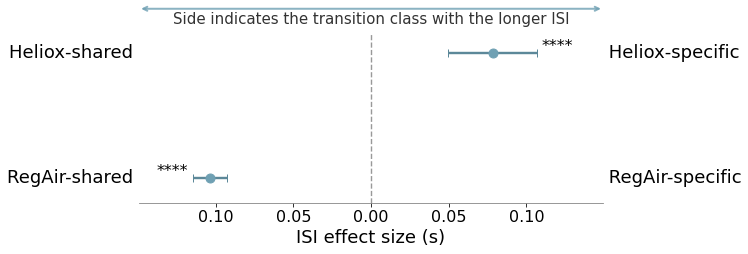

condition    beta   ci_lo    ci_hi         p
   heliox 0.07838 0.04977    0.107 7.858e-08
   regair -0.1038 -0.1148 -0.09279 4.038e-76


In [4]:
# Fig. 3D on its own: ISI on condition-specific vs shared transitions in starlings
# Same two models as above (the ones the Results text reports), drawn the way the original
# transition notebook drew this panel. Run after the models cell (uses effects).
LEFT = {'heliox': 'Heliox-shared', 'regair': 'RegAir-shared'}
RIGHT = {'heliox': 'Heliox-specific', 'regair': 'RegAir-specific'}
NOTE = 'Side indicates the transition class with the longer ISI'
TITLE = None            # e.g. 'ISI Differences by Syllable Transition Type'; the panel letter goes on at assembly

fig, ax = plt.subplots(figsize=(10.5, 3.7))
y = {'heliox': 1, 'regair': 0}
max_abs = 1.3 * np.abs(effects[['ci_lo', 'ci_hi']].to_numpy()).max()      # symmetric axis, as in the original
for e in effects.itertuples():
    ax.errorbar(e.beta, y[e.condition], xerr=[[e.beta - e.ci_lo], [e.ci_hi - e.beta]], fmt='o', color='#6FA0B3',
                ecolor='#5C8899', elinewidth=2.4, capsize=4, markersize=9, zorder=3)        # point +/- 95% CI
    stars = '****' if e.p < 1e-4 else '***' if e.p < 1e-3 else '**' if e.p < 1e-2 else '*' if e.p < 0.05 else 'ns'
    # stars sit just past the end of the interval, on the side the estimate falls
    x_star = e.ci_hi + 0.02 * max_abs if e.beta >= 0 else e.ci_lo - 0.02 * max_abs
    ax.text(x_star, y[e.condition] + 0.05, stars, ha='left' if e.beta >= 0 else 'right', va='center', fontsize=16)
    ax.text(-max_abs, y[e.condition], LEFT[e.condition] + ' ', ha='right', va='center', fontsize=18, clip_on=False)
    ax.text(max_abs, y[e.condition], ' ' + RIGHT[e.condition], ha='left', va='center', fontsize=18, clip_on=False)
ax.axvline(0, color='0.6', ls='--', lw=1.4)
ax.set_xlim(-max_abs, max_abs)
ax.set_ylim(-0.2, 1.15)
ax.set_yticks([])
ax.annotate('', xy=(max_abs, 1.35), xytext=(-max_abs, 1.35), annotation_clip=False,
            arrowprops=dict(arrowstyle='<->', color='#6FA0B3', lw=2, alpha=0.8))
ax.text(0, 1.23, NOTE, ha='center', fontsize=15, alpha=0.8)
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{abs(v):.2f}'))    # magnitude; the side gives the sign
ax.tick_params(axis='x', labelsize=16)
ax.set_xlabel('ISI effect size (s)', fontsize=18)
if TITLE:
    ax.set_title(TITLE, fontsize=19, fontweight='bold', pad=40)
for side in ('top', 'right', 'left'):
    ax.spines[side].set_visible(False)
ax.spines['bottom'].set_color('0.5')
plt.tight_layout()
fig.savefig(os.path.join(FIG_DIR, 'fig3D_transition_isi.png'), dpi=600, bbox_inches='tight')
fig.savefig(os.path.join(FIG_DIR, 'fig3D_transition_isi.pdf'), bbox_inches='tight')
plt.show()
print(effects[['condition', 'beta', 'ci_lo', 'ci_hi', 'p']].to_string(index=False, float_format=lambda v: f'{v:.4g}'))